# La espiral: fronteras de decisión

Los apuntes del curso CS231n de Stanford tienen un ejemplo que se volvió clásico: tres clases de puntos enrolladas en una espiral. Un clasificador lineal no puede con ellas, y una red con una capa oculta sí. Este notebook lo reproduce en PyTorch y mira **la frontera de decisión**: la línea que separa las zonas donde el modelo predice cada clase. Dibujarla es la forma más directa de ver qué puede representar un modelo, la misma intuición que buscan los videos de Welch Labs.

Luego se repiten dos experimentos de *Neural Networks Part 1* de CS231n: qué pasa con la frontera al cambiar el tamaño de la capa oculta y al cambiar la fuerza de la regularización.

**Contenido**

1. Preparación
2. Los datos
3. Un clasificador lineal
4. Una red con una capa oculta
5. De qué está hecha la frontera
6. El tamaño de la capa oculta
7. Regularización
8. Resumen y ejercicios

## 1. Preparación

In [1]:
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

torch.manual_seed(0)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 2. Los datos

Cada clase es un brazo de la espiral. El punto $i$ de la clase $j$ está a un radio $r$ que crece de 0 a 1, y a un ángulo $t$ que avanza 4 radianes por clase, con algo de ruido. Es la receta de CS231n.

Generamos dos conjuntos con la misma receta y distinto ruido: uno para entrenar y otro de **prueba**, que el modelo no ve durante el entrenamiento. La exactitud en el de prueba dice si el modelo aprendió la forma de la espiral o solo memorizó los puntos.

entrenamiento: torch.Size([300, 2]) torch.Size([300])   prueba: torch.Size([300, 2])


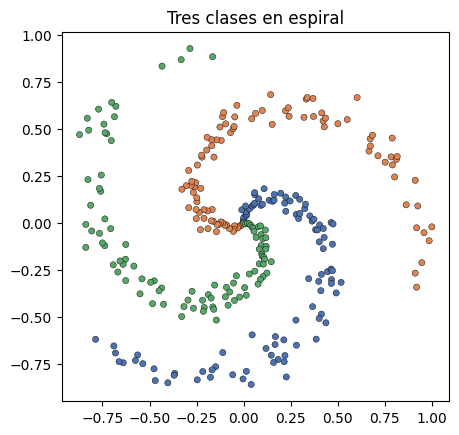

In [2]:
def espiral(puntos_por_clase=100, clases=3, ruido=0.2, semilla=0):
    generador = torch.Generator().manual_seed(semilla)
    X, y = [], []
    for clase in range(clases):
        radio = torch.linspace(0, 1, puntos_por_clase)
        angulo = torch.linspace(clase * 4, (clase + 1) * 4, puntos_por_clase)
        angulo = angulo + torch.randn(puntos_por_clase, generator=generador) * ruido
        X.append(torch.stack([radio * torch.sin(angulo), radio * torch.cos(angulo)], dim=1))
        y.append(torch.full((puntos_por_clase,), clase))
    return torch.cat(X), torch.cat(y)


X, y = espiral(semilla=0)
X_prueba, y_prueba = espiral(semilla=1)
print("entrenamiento:", X.shape, y.shape, "  prueba:", X_prueba.shape)

colores = ListedColormap(["#4C72B0", "#DD8452", "#55A868"])
plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=colores, s=20, edgecolors="k", linewidths=0.3)
plt.title("Tres clases en espiral")
plt.gca().set_aspect("equal")
plt.show()

Dos funciones auxiliares se usan en todo el notebook. `entrenar` hace descenso de gradiente con el lote completo y entropía cruzada, y devuelve la exactitud en entrenamiento y en prueba. `dibujar_frontera` evalúa el modelo en una grilla fina de puntos y pinta cada uno con la clase que predice.

In [3]:
def exactitud(modelo, X, y):
    with torch.no_grad():
        return (modelo(X).argmax(dim=1) == y).float().mean().item()


def entrenar(modelo, pasos=5000, lr=1.0, weight_decay=0.0):
    optimizador = torch.optim.SGD(modelo.parameters(), lr=lr, weight_decay=weight_decay)
    criterio = nn.CrossEntropyLoss()
    for _ in range(pasos):
        perdida = criterio(modelo(X), y)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
    return perdida.item(), exactitud(modelo, X, y), exactitud(modelo, X_prueba, y_prueba)


def dibujar_frontera(eje, modelo, titulo, resolucion=300):
    a, b = torch.meshgrid(torch.linspace(-1.2, 1.2, resolucion), torch.linspace(-1.2, 1.2, resolucion), indexing="xy")
    grilla = torch.stack([a.flatten(), b.flatten()], dim=1)
    with torch.no_grad():
        prediccion = modelo(grilla).argmax(dim=1).reshape(resolucion, resolucion)
    eje.contourf(a, b, prediccion, levels=[-0.5, 0.5, 1.5, 2.5], cmap=colores, alpha=0.35)
    eje.scatter(X[:, 0], X[:, 1], c=y, cmap=colores, s=12, edgecolors="k", linewidths=0.3)
    eje.set_xlim(-1.2, 1.2)
    eje.set_ylim(-1.2, 1.2)
    eje.set_aspect("equal")
    eje.set_xticks([])
    eje.set_yticks([])
    eje.set_title(titulo)

## 3. Un clasificador lineal

Primero lo más simple: una capa `nn.Linear(2, 3)` que da un puntaje por clase, y la entropía cruzada (que incluye el softmax, ver `04-matematica-de-pytorch/03_funciones_de_perdida`). La clase predicha es la de mayor puntaje.

In [4]:
torch.manual_seed(0)
lineal = nn.Linear(2, 3)
perdida, en_entrenamiento, en_prueba = entrenar(lineal)
print(f"lineal: pérdida {perdida:.3f}   exactitud entrenamiento {en_entrenamiento:.0%}   prueba {en_prueba:.0%}")

lineal: pérdida 0.745   exactitud entrenamiento 52%   prueba 53%


Acierta la mitad, poco más que el 33% de adivinar al azar. La frontera muestra por qué:

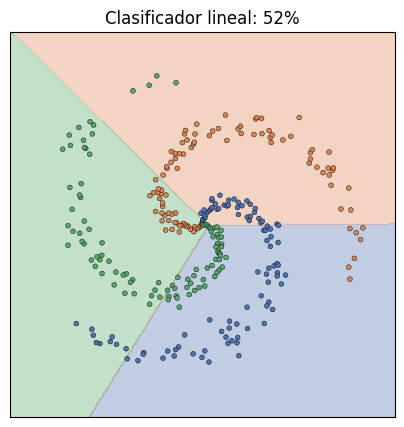

In [5]:
fig, eje = plt.subplots(figsize=(5, 5))
dibujar_frontera(eje, lineal, f"Clasificador lineal: {en_entrenamiento:.0%}")
plt.show()

Con un modelo lineal, cada zona es un **sector convexo** limitado por rectas. Esto pasa siempre: la clase $j$ gana donde su puntaje $w_j \cdot x + b_j$ supera a los otros dos, y cada una de esas comparaciones es un semiplano. La zona de la clase es la intersección de dos semiplanos, y una intersección de semiplanos es convexa. Un brazo de espiral no es convexo, así que no hay forma de acomodarlo en una de estas zonas.

## 4. Una red con una capa oculta

CS231n usa 100 neuronas ocultas con ReLU:

red: pérdida 0.024   exactitud entrenamiento 99%   prueba 99%


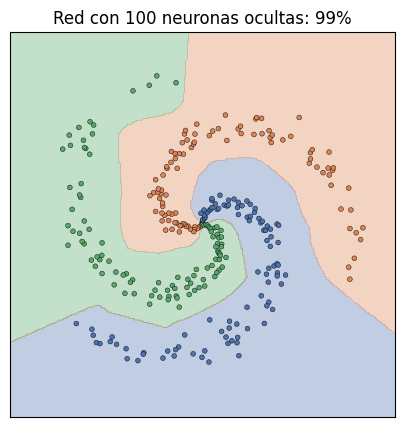

In [6]:
torch.manual_seed(0)
red = nn.Sequential(nn.Linear(2, 100), nn.ReLU(), nn.Linear(100, 3))
perdida, en_entrenamiento, en_prueba = entrenar(red)
print(f"red: pérdida {perdida:.3f}   exactitud entrenamiento {en_entrenamiento:.0%}   prueba {en_prueba:.0%}")

fig, eje = plt.subplots(figsize=(5, 5))
dibujar_frontera(eje, red, f"Red con 100 neuronas ocultas: {en_entrenamiento:.0%}")
plt.show()

Casi todos los puntos de entrenamiento y de prueba quedan bien clasificados, y las zonas siguen la forma de los brazos.

## 5. De qué está hecha la frontera

Una neurona oculta $\mathrm{ReLU}(w \cdot x + b)$ vale 0 de un lado de la recta $w \cdot x + b = 0$ y crece linealmente del otro. Dentro de cada región donde ninguna neurona cambia de estado, la red completa es una función lineal. Así que la red divide el plano con sus 100 rectas en muchos polígonos, y en cada polígono se comporta como un clasificador lineal distinto.

Dibujamos las 100 rectas sobre la frontera:

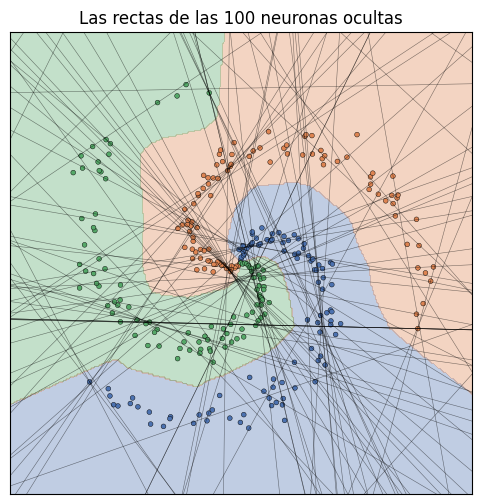

In [7]:
fig, eje = plt.subplots(figsize=(6, 6))
dibujar_frontera(eje, red, "Las rectas de las 100 neuronas ocultas")

with torch.no_grad():
    pesos = red[0].weight.detach()
    sesgos = red[0].bias.detach()
x1 = torch.linspace(-1.2, 1.2, 2)
for (w1, w2), b in zip(pesos, sesgos):
    if abs(w2) > 1e-6:
        eje.plot(x1, -(w1 * x1 + b) / w2, color="black", linewidth=0.4, alpha=0.5)
eje.set_xlim(-1.2, 1.2)
eje.set_ylim(-1.2, 1.2)
plt.show()

Los quiebres de la frontera caen sobre esas rectas: la frontera es una línea poligonal hecha de trozos de ellas. Es la misma idea de `02_xor_y_redes_feedforward`, ahora en dos dimensiones: más neuronas son más rectas, y más rectas permiten una frontera con más quiebres.

Muchas rectas pasan por el centro, donde los brazos están más juntos y la frontera necesita más detalle.

## 6. El tamaño de la capa oculta

CS231n compara redes con 3, 6 y 20 neuronas ocultas. Repetimos el experimento con nuestra espiral, y agregamos las de 100:

 ancho   pérdida   entrenamiento   prueba


     3     0.535            69%      67%


     6     0.181            96%      96%


    20     0.026            99%      99%


   100     0.024            99%      99%


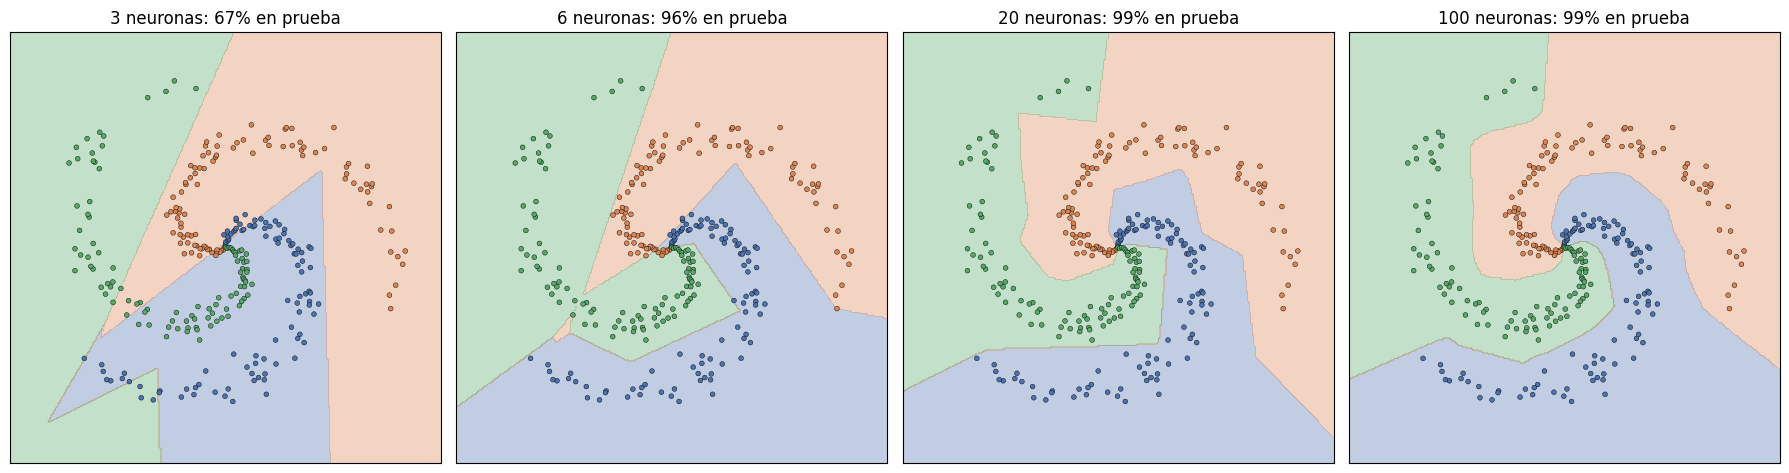

In [8]:
anchos = [3, 6, 20, 100]
fig, ejes = plt.subplots(1, len(anchos), figsize=(18, 4.8))
print(" ancho   pérdida   entrenamiento   prueba")
for eje, ancho in zip(ejes, anchos):
    torch.manual_seed(0)
    modelo = nn.Sequential(nn.Linear(2, ancho), nn.ReLU(), nn.Linear(ancho, 3))
    perdida, en_entrenamiento, en_prueba = entrenar(modelo)
    print(f"{ancho:6d} {perdida:9.3f} {en_entrenamiento:14.0%} {en_prueba:8.0%}")
    dibujar_frontera(eje, modelo, f"{ancho} neuronas: {en_prueba:.0%} en prueba")
plt.tight_layout()
plt.show()

Con 3 neuronas la frontera tiene muy pocos quiebres y no alcanza a enrollarse. Con 6 ya sigue la espiral a grandes rasgos, y con 20 la sigue bien. Pasar de 20 a 100 apenas cambia la exactitud, pero la frontera se vuelve más suave: hay más rectas para repartir los quiebres.

Con esta espiral, ni siquiera la red de 100 neuronas memoriza: la exactitud de prueba sigue a la de entrenamiento. Con menos datos y más ruido la historia cambia, y para eso existe la regularización.

## 7. Regularización

CS231n recomienda no achicar la red para evitar el sobreajuste, sino usar una red grande y **regularizarla**. La regularización L2 suma a la pérdida un castigo $\frac{\lambda}{2}\sum w^2$ por pesos grandes. Con SGD es exactamente el parámetro `weight_decay` (se demostró en `04-matematica-de-pytorch/04_optimizadores`, sección 3).

Para que haya algo que regularizar, ponemos a la red en una situación más difícil: una espiral con más ruido (los brazos se mezclan en los bordes) y solo 30 puntos de entrenamiento por clase. La prueba se hace con 1000 puntos por clase, para que la exactitud de prueba sea una estimación estable.

     λ   pérdida   entrenamiento   prueba


     0     0.043          97.8%    91.3%


0.0001     0.058          97.8%    91.6%


 0.001     0.191          96.7%    89.7%


  0.01     0.665          72.2%    67.9%


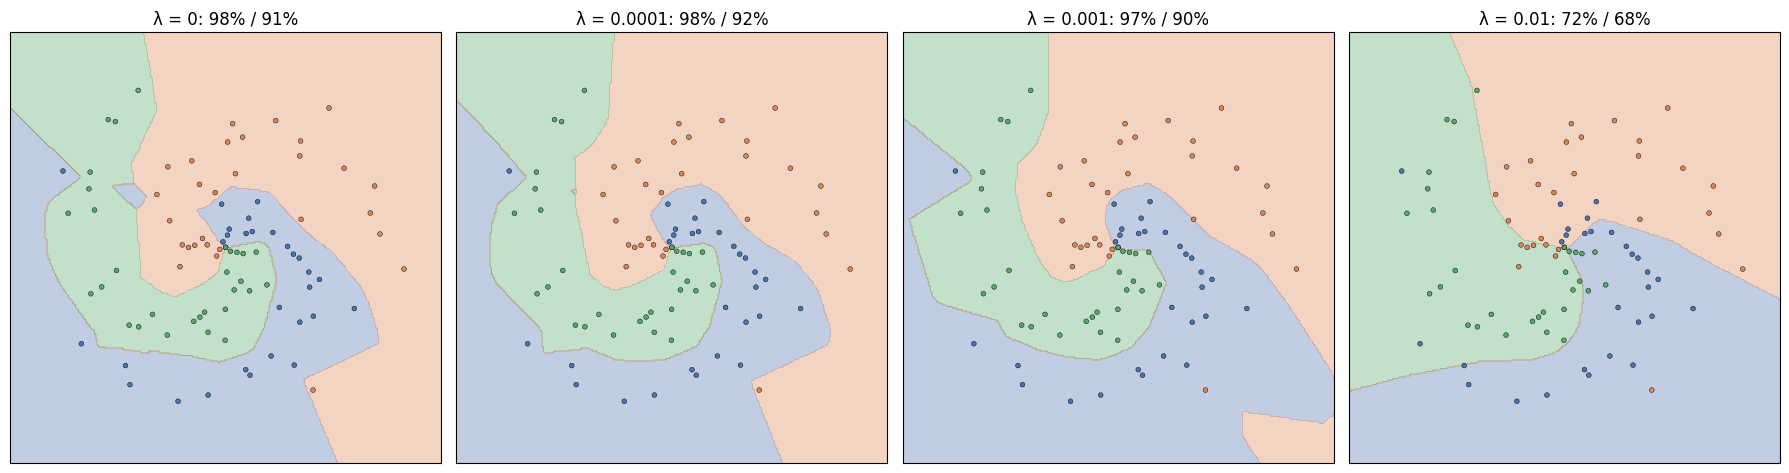

In [9]:
X, y = espiral(puntos_por_clase=30, ruido=0.5, semilla=0)
X_prueba, y_prueba = espiral(puntos_por_clase=1000, ruido=0.5, semilla=1)

lambdas = [0.0, 1e-4, 1e-3, 1e-2]
fig, ejes = plt.subplots(1, len(lambdas), figsize=(18, 4.8))
print("     λ   pérdida   entrenamiento   prueba")
for eje, lam in zip(ejes, lambdas):
    torch.manual_seed(0)
    modelo = nn.Sequential(nn.Linear(2, 100), nn.ReLU(), nn.Linear(100, 3))
    perdida, en_entrenamiento, en_prueba = entrenar(modelo, pasos=10000, weight_decay=lam)
    print(f"{lam:6g} {perdida:9.3f} {en_entrenamiento:14.1%} {en_prueba:8.1%}")
    dibujar_frontera(eje, modelo, f"λ = {lam:g}: {en_entrenamiento:.0%} / {en_prueba:.0%}")
plt.tight_layout()
plt.show()

Los títulos muestran la exactitud en entrenamiento y en prueba.

- **Sin regularización** hay una brecha de unos 6 puntos entre entrenamiento (98%) y prueba (91%). Parte de lo aprendido es ruido de estos 90 puntos en particular: por ejemplo, la isla azul dentro de la zona naranja, armada alrededor de un solo punto.
- **Con λ = 0.0001** la isla casi desaparece y la frontera se suaviza. La exactitud de prueba sube apenas, de 91.3% a 91.6%.
- **Con λ = 0.001** la frontera es más suave todavía, pero las dos exactitudes bajan: ya no solo se pierde ruido, también algo de la forma de la espiral.
- **Con λ = 0.01** el castigo domina. Los pesos quedan tan chicos que la red no puede enrollar la frontera, y las zonas vuelven a parecerse a los sectores del clasificador lineal.

En este problema la regularización compra muy poco: el mejor λ mejora la prueba en unas décimas, y uno un poco más grande ya la empeora. Probablemente buena parte de la brecha no se puede cerrar, porque con este ruido los brazos se mezclan cerca del centro y hay puntos de prueba que caen dentro del brazo de otra clase.

La lección práctica es otra: λ es un **hiperparámetro**. No se aprende con el gradiente, se elige comparando valores en datos que el modelo no usó para entrenar, y el que conviene puede ser muy chico o incluso cero. El sobreajuste, y cómo la regularización lo corrige, se ven mucho más claros en `04_ajuste_polinomial_y_sobreajuste`.

## 8. Resumen

- Un clasificador lineal divide el plano en zonas convexas, una por clase. Por eso no puede con datos como la espiral, cuyos brazos no son convexos.
- Una capa oculta con ReLU divide el plano en polígonos con las rectas de sus neuronas, y en cada polígono actúa como un clasificador lineal distinto. La frontera de decisión es una poligonal hecha de trozos de esas rectas.
- Con muy pocas neuronas, la frontera no tiene suficientes quiebres. Con más, sigue la forma de los datos y se suaviza.
- Con pocos datos y mucho ruido, una red grande sin regularizar aprende parte del ruido. La regularización L2 (`weight_decay`) suaviza la frontera, aunque en la espiral casi no mejora la exactitud de prueba. Demasiada regularización devuelve un modelo casi lineal.
- La exactitud en un conjunto de prueba, que el modelo no vio, es la que dice si aprendió la forma de los datos o los memorizó.

## Ejercicios

1. Cambia la espiral a 5 clases (`clases=5`). ¿Cuántas neuronas ocultas necesita la red para llegar a 90% en prueba?
2. Agrega una segunda capa oculta: `nn.Linear(2, 20), nn.ReLU(), nn.Linear(20, 20), nn.ReLU(), nn.Linear(20, 3)`. Compárala con la red de una capa con 100 neuronas. ¿Cuántos parámetros tiene cada una? (Usa `sum(p.numel() for p in modelo.parameters())`.)
3. En la sección 3, agrega a la entrada las coordenadas polares: el radio $\sqrt{x_1^2 + x_2^2}$ y el ángulo `torch.atan2(x1, x2)`. ¿Llega ahora el clasificador lineal a más del 50%? ¿Por qué no llega al 100%?
4. En la sección 7, cambia `weight_decay` por una red más chica sin regularización (6 y 20 neuronas). ¿Qué opción da mejor exactitud de prueba con la espiral ruidosa: una red chica, o una grande con λ = 0.001?
5. Cambia `nn.ReLU()` por `nn.Tanh()` en la red de la sección 4 y dibuja la frontera. ¿Sigue siendo poligonal? Explica por qué, usando la sección 5.